# B1 — APTOS2019

Conservative training augmentation may improve generalization while preserving retinal field of view.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

Exact recorded main training module matched by SHA-256 to [the archived source](https://github.com/salmakamila126/Diabetic-Rethinography/blob/3a563c67fef82454ce2ed34858615bd456424a13/novelty/foundation_adaptation.py). The optional CLI uses the current [foundation adaptation](../../novelty/foundation_adaptation.py) for a separately recorded new run.

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A linear categorical head emits five logits. Parameter counts are not published in this run evidence.

EXIF transpose and RGB, then the pinned official processor at 224 px for resize/crop, rescale and normalization. B1 train-only augmentation is keyed by seed, epoch and image ID. It applies horizontal flip (p=0.50), field-of-view guarded rotation (p=0.50, ±7°), brightness (p=0.30, factor 0.90–1.10), and contrast (p=0.30, factor 0.90–1.10), in that order.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'B1', 'APTOS2019'
EVIDENCE = 'novelty/convnext_b0_b4/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [r for r in blob['runs'] if r['dataset'] == DATASET and (r['arm'].startswith('B4-') if METHOD == 'B4' else r['arm'] == METHOD)]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CHECKPOINT_SHA256 = '3f2a3ff48e9fe14e70e75cdb8c2f7a4003e3c38fe24e584884351b9b145fe6e4'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## B1 recorded configuration and history

[Authoritative aggregate JSON](../../novelty/convnext_b0_b4/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| model_kind | convnext_tiny |
| mode | full |
| seed | 42 |
| epochs | 20 |
| micro_batch | 32 |
| accumulation | 1 |
| effective_batch | 32 |
| precision | bf16 |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| selection | max validation macro-F1; tie lower validation loss; tie earliest epoch |
| training_loss | ordinary CE |
| implementation_sha256 | 2b011e422c40f52a03a3d0aa89e0d18285875da1946058c265cc07747a61f300 |
| manifest_sha256 | 73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854 |
| train / validation counts | {'train': 2930, 'val': 366} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": {
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0",
    "protocol": {
      "brightness_factor": [
        0.9,
        1.1
      ],
      "brightness_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "fov_proxy_threshold_max_channel": 8,
      "horizontal_flip_probability": 0.5,
      "minimum_fov_proxy_retention": 0.99,
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "rotation_attempts": 8,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "rotation_fill": [
        0,
        0,
        0
      ],
      "rotation_probability": 0.5,
      "rotation_resample": "BICUBIC"
    }
  }
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.819194 | 0.703754 | 0.358487 | 0.640279 | 0.588873 | 0.522184 |
| 2 | 0.549958 | 0.791468 | 0.498855 | 0.752059 | 0.814035 | 0.304437 |
| 3 | 0.475476 | 0.822867 | 0.615585 | 0.802764 | 0.856732 | 0.251536 |
| 4 | 0.431662 | 0.831741 | 0.655969 | 0.819106 | 0.873534 | 0.235154 |
| 5 | 0.397322 | 0.84198 | 0.67431 | 0.8312 | 0.884756 | 0.219795 |
| 6 | 0.364062 | 0.861433 | 0.722216 | 0.85441 | 0.898773 | 0.194198 |
| 7 | 0.33272 | 0.877133 | 0.755931 | 0.872112 | 0.915384 | 0.168259 |
| 8 | 0.303373 | 0.886348 | 0.779399 | 0.882921 | 0.925816 | 0.153242 |
| 9 | 0.274023 | 0.897611 | 0.801307 | 0.894604 | 0.926054 | 0.145051 |
| 10 | 0.236611 | 0.916382 | 0.832062 | 0.914017 | 0.944994 | 0.112969 |
| 11 | 0.211575 | 0.929693 | 0.863763 | 0.927976 | 0.955073 | 0.094198 |
| 12 | 0.188871 | 0.935495 | 0.869388 | 0.933909 | 0.954069 | 0.0904437 |
| 13 | 0.163685 | 0.946075 | 0.894355 | 0.945373 | 0.967512 | 0.0699659 |
| 14 | 0.140739 | 0.956314 | 0.914773 | 0.955719 | 0.975094 | 0.0552901 |
| 15 | 0.124275 | 0.959386 | 0.922894 | 0.958949 | 0.974165 | 0.0542662 |
| 16 | 0.0999242 | 0.969625 | 0.937453 | 0.969321 | 0.985477 | 0.0361775 |
| 17 | 0.0871695 | 0.97372 | 0.948816 | 0.973559 | 0.986054 | 0.0324232 |
| 18 | 0.0728501 | 0.979181 | 0.958048 | 0.979118 | 0.987995 | 0.0266212 |
| 19 | 0.0663933 | 0.980205 | 0.960621 | 0.980038 | 0.989515 | 0.0242321 |
| 20 | 0.0628802 | 0.977474 | 0.955385 | 0.977406 | 0.986887 | 0.0290102 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.626554 | 0.756831 | 0.423765 | 0.709673 | 0.787403 | 0.344262 |
| 2 | 0.566752 | 0.765027 | 0.44423 | 0.723281 | 0.811341 | 0.322404 |
| 3 | 0.520084 | 0.79235 | 0.549204 | 0.767044 | 0.858902 | 0.273224 |
| 4 | 0.495171 | 0.81694 | 0.630139 | 0.805569 | 0.875781 | 0.243169 |
| 5 | 0.514562 | 0.811475 | 0.611745 | 0.79709 | 0.877881 | 0.243169 |
| 6 | 0.489983 | 0.814208 | 0.638277 | 0.805168 | 0.887347 | 0.234973 |
| 7 | 0.496804 | 0.811475 | 0.653912 | 0.809099 | 0.888616 | 0.240437 |
| 8 | 0.479138 | 0.819672 | 0.654684 | 0.814044 | 0.896213 | 0.226776 |
| 9 | 0.487987 | 0.822404 | 0.674615 | 0.822698 | 0.896674 | 0.226776 |
| 10 | 0.491469 | 0.822404 | 0.678657 | 0.822857 | 0.900423 | 0.221311 |
| 11 | 0.51158 | 0.825137 | 0.701022 | 0.828626 | 0.901277 | 0.224044 |
| 12 | 0.519752 | 0.836066 | 0.689837 | 0.833102 | 0.900622 | 0.210383 |
| 13 | 0.54851 | 0.836066 | 0.681979 | 0.831236 | 0.899853 | 0.210383 |
| 14 | 0.520608 | 0.81694 | 0.673737 | 0.816705 | 0.893512 | 0.234973 |
| 15 | 0.554203 | 0.825137 | 0.691328 | 0.826545 | 0.89203 | 0.23224 |
| 16 | 0.604944 | 0.830601 | 0.701124 | 0.832144 | 0.898623 | 0.221311 |
| 17 | 0.587768 | 0.822404 | 0.687869 | 0.82353 | 0.89759 | 0.229508 |
| 18 | 0.605025 | 0.814208 | 0.673331 | 0.815615 | 0.889305 | 0.245902 |
| 19 | 0.629242 | 0.814208 | 0.677903 | 0.815109 | 0.892538 | 0.240437 |
| 20 | 0.660018 | 0.81694 | 0.686242 | 0.81925 | 0.895035 | 0.234973 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 663.732 | 0.81292 | 651.36 | 0.334525 | 4.41443 | 450.229 | 2665480192 | 2932748288 | 64 | 25 | 0 |
| 2 | 649.83 | 0.808403 | 637.782 | 0.335429 | 4.50887 | 452.745 | 2665480192 | 2945142784 | 57 | 29 | 1 |
| 3 | 640.547 | 0.801238 | 628.495 | 0.330266 | 4.57422 | 456.793 | 2665480192 | 2945142784 | 43 | 33 | 1 |
| 4 | 615.717 | 0.81538 | 603.66 | 0.337633 | 4.75868 | 448.87 | 2665480192 | 2945142784 | 36 | 31 | 2 |
| 5 | 601.688 | 0.81426 | 589.674 | 0.339029 | 4.86964 | 449.488 | 2665480192 | 2945142784 | 43 | 26 | 12 |
| 6 | 609.533 | 0.812258 | 597.514 | 0.335415 | 4.80696 | 450.596 | 2665480192 | 2982387712 | 37 | 31 | 10 |
| 7 | 604.931 | 0.810288 | 592.9 | 0.337216 | 4.84353 | 451.691 | 2665480192 | 2982387712 | 34 | 35 | 14 |
| 8 | 612.571 | 0.803304 | 600.547 | 0.332405 | 4.78312 | 455.618 | 2665480192 | 2982387712 | 32 | 34 | 11 |
| 9 | 621.925 | 0.808063 | 609.903 | 0.332685 | 4.71118 | 452.935 | 2665480192 | 2982387712 | 34 | 31 | 13 |
| 10 | 629.52 | 0.810534 | 617.485 | 0.336122 | 4.65434 | 451.554 | 2665480192 | 3034644480 | 34 | 31 | 15 |
| 11 | 623.911 | 0.81522 | 611.882 | 0.340328 | 4.69618 | 448.958 | 2665480192 | 3034644480 | 29 | 35 | 14 |
| 12 | 622.359 | 0.805594 | 610.318 | 0.3336 | 4.7079 | 454.323 | 2665480192 | 3034644480 | 36 | 24 | 18 |
| 13 | 628.685 | 0.810352 | 616.652 | 0.336666 | 4.66052 | 451.656 | 2665480192 | 3034644480 | 38 | 22 | 19 |
| 14 | 627.709 | 0.809522 | 615.649 | 0.33399 | 4.66777 | 452.119 | 2665480192 | 3034644480 | 33 | 34 | 18 |
| 15 | 616.691 | 0.814778 | 604.652 | 0.338064 | 4.75116 | 449.202 | 2665480192 | 3034644480 | 33 | 31 | 22 |
| 16 | 631.002 | 0.805978 | 618.974 | 0.333506 | 4.6434 | 454.107 | 2665480192 | 3034644480 | 33 | 29 | 23 |
| 17 | 636.666 | 0.820722 | 624.618 | 0.345241 | 4.6021 | 445.949 | 2665480192 | 3112632320 | 31 | 34 | 22 |
| 18 | 616.516 | 0.810139 | 604.489 | 0.335745 | 4.75251 | 451.774 | 2665480192 | 3112632320 | 31 | 37 | 27 |
| 19 | 615.396 | 0.817243 | 603.342 | 0.340003 | 4.76116 | 447.847 | 2665480192 | 3112632320 | 33 | 35 | 26 |
| 20 | 627.408 | 0.80629 | 615.37 | 0.332519 | 4.67001 | 453.931 | 2665480192 | 3112632320 | 34 | 33 | 28 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | — | 1 | True |
| 2 | 1e-05 | 0.001 | — | 2 | True |
| 3 | 1e-05 | 0.001 | — | 3 | True |
| 4 | 1e-05 | 0.001 | — | 4 | True |
| 5 | 1e-05 | 0.001 | — | 4 | False |
| 6 | 1e-05 | 0.001 | — | 6 | True |
| 7 | 1e-05 | 0.001 | — | 7 | True |
| 8 | 1e-05 | 0.001 | — | 8 | True |
| 9 | 1e-05 | 0.001 | — | 9 | True |
| 10 | 1e-05 | 0.001 | — | 10 | True |
| 11 | 1e-05 | 0.001 | — | 11 | True |
| 12 | 1e-05 | 0.001 | — | 11 | False |
| 13 | 1e-05 | 0.001 | — | 11 | False |
| 14 | 1e-05 | 0.001 | — | 11 | False |
| 15 | 1e-05 | 0.001 | — | 11 | False |
| 16 | 1e-05 | 0.001 | — | 16 | True |
| 17 | 1e-05 | 0.001 | — | 16 | False |
| 18 | 1e-05 | 0.001 | — | 16 | False |
| 19 | 1e-05 | 0.001 | — | 16 | False |
| 20 | 1e-05 | 0.001 | — | 16 | False |

## B1 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 16 | 0.830601 | 0.701124 | 0.832144 | 0.898623 | 0.221311 | 304 | 62 | 33 | 29 |

Frozen validation only. The selected checkpoint SHA-256 is `3f2a3ff48e9fe14e70e75cdb8c2f7a4003e3c38fe24e584884351b9b145fe6e4`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 174 | 6 | 0 | 0 | 0 |
| 1 | 1 | 25 | 9 | 0 | 0 |
| 2 | 0 | 13 | 78 | 3 | 7 |
| 3 | 0 | 0 | 7 | 9 | 4 |
| 4 | 0 | 2 | 8 | 2 | 18 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 96.6667 | 3.33333 | 0 | 0 | 0 |
| 1 | 2.85714 | 71.4286 | 25.7143 | 0 | 0 |
| 2 | 0 | 12.8713 | 77.2277 | 2.9703 | 6.93069 |
| 3 | 0 | 0 | 35 | 45 | 20 |
| 4 | 0 | 6.66667 | 26.6667 | 6.66667 | 60 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.994286 | 0.966667 | 0.980282 | 180 | 174 |
| 1 | 0.543478 | 0.714286 | 0.617284 | 35 | 25 |
| 2 | 0.764706 | 0.772277 | 0.768473 | 101 | 78 |
| 3 | 0.642857 | 0.45 | 0.529412 | 20 | 9 |
| 4 | 0.62069 | 0.6 | 0.610169 | 30 | 18 |

Minority-grade predictions on the diagonal were grade 1 25/35, grade 3 9/20. The largest off-diagonal counts were 2 → 1 (13), 1 → 2 (9), 4 → 2 (8). The matrix gives 45 adjacent errors and 17 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Recorded figures

[Learning curves, SVG](../../novelty/convnext_b0_b4/APTOS2019_B1_learning_curves.svg) · [Original PNG](../../novelty/convnext_b0_b4/APTOS2019_B1_confusion_matrix.png). The saved cell output is the original PNG. Rows are true grades and columns are predicted grades.

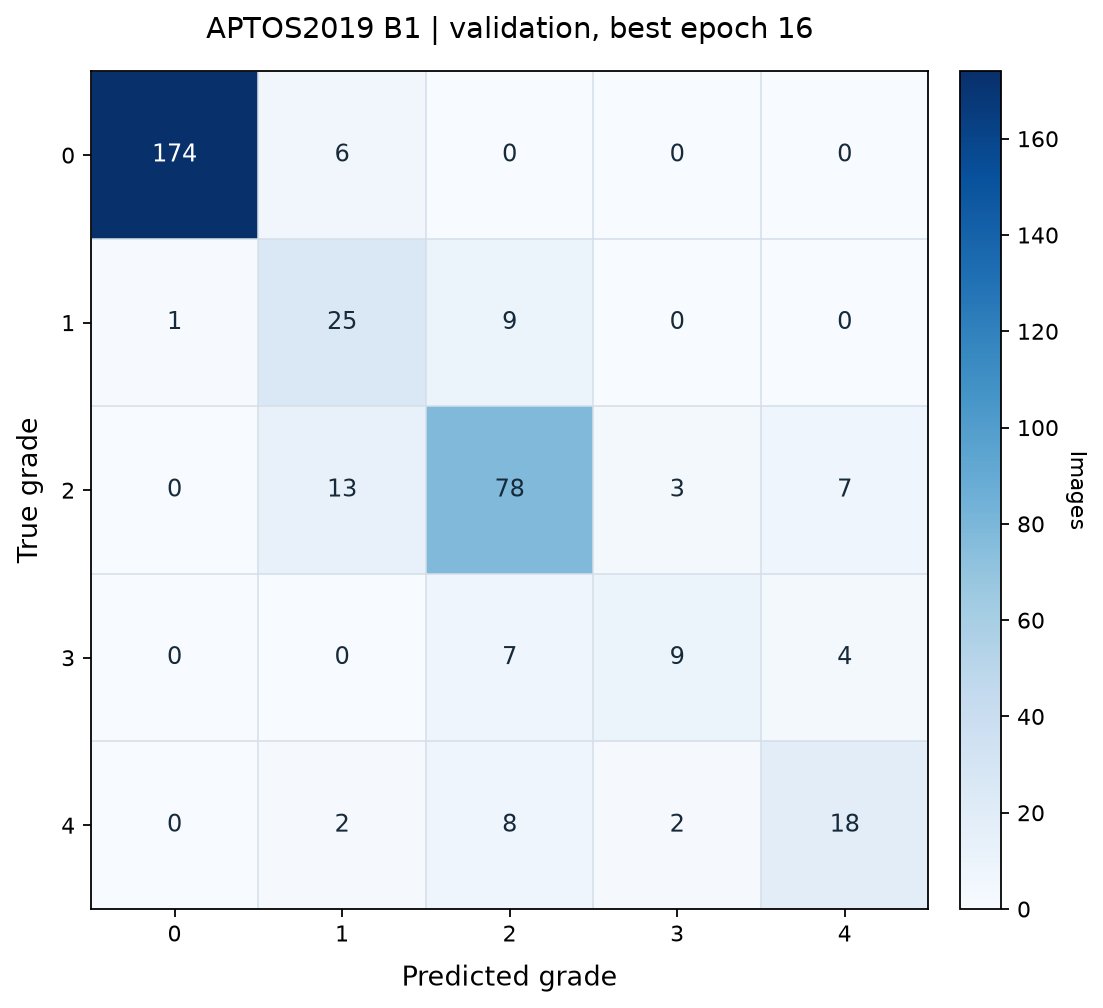

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B1_confusion_matrix.png')))

The next output displays the original train and validation learning curves. Metric coverage follows the corresponding recorded history.

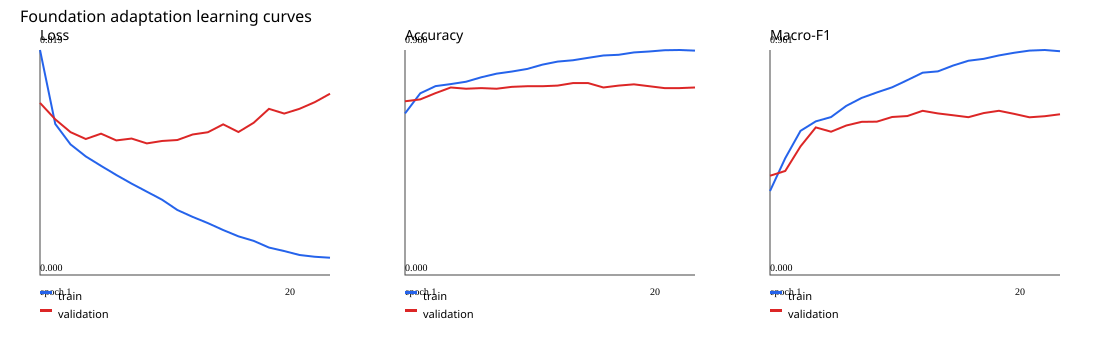

In [ ]:
from IPython.display import SVG
display(SVG(filename=str(ROOT / 'novelty/convnext_b0_b4/APTOS2019_B1_learning_curves.svg')))

## Interpretation and limits

Compared with B0 on this validation split, macro-F1 changed by +0.027438, grade 1 recall by +0.0571, and grade 3 recall by -0.0500.

Screening comparisons share validation data and need independent confirmation. A selected checkpoint is not a final-test result. See the [baseline rationale and audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md#b0b4-mapping).

## Optional execution of the authentic workflow

Set the external `DR_ARTIFACT_ROOT`, `DR_CONVNEXT_SNAPSHOT` and for writing steps `DR_NOTEBOOK_RUN_DIR`. Use the protocol's reviewed cache roots, size budgets and paths when applicable. `DR_MANIFEST_SOURCE_ROOT` supports moved roots for E5–E7. Authorize the local snapshot explicitly via `DR_TRUST_LEGACY_BIN=1` where required. GPU actions also require `DR_GPU_ALLOCATION_CONFIRMED=1`. 

The [shared workflow bridge](../experiment_workflow.py) lists the exact environment keys and dispatches to the original CLI. Choose one step and enable its switch. Outputs must use a fresh external location. Report identity and cache validity remain enforced by the runner.

In [ ]:
from notebooks.experiment_workflow import run_step

ACTION = None
RUN_PREFLIGHT = False
RUN_CACHE = False
RUN_INPUT_VERIFICATION = False
RUN_GPU_SMOKE = False
RUN_BENCHMARK = False
RUN_TRAINING = False
RUN_CHECKPOINT_EXPORT = False
RUN_PRUNING = False
RUN_FINAL_TEST = False
if RUN_CHECKPOINT_EXPORT or RUN_PRUNING or RUN_FINAL_TEST:
    raise ValueError("Export, pruning and final-test inference are outside this workflow.")
run_step(ROOT, METHOD, DATASET, ACTION, CONFIG, {
    "preflight": RUN_PREFLIGHT, "estimate-cache": RUN_PREFLIGHT, "prepare-cache": RUN_CACHE,
    "verify-inputs": RUN_INPUT_VERIFICATION, "smoke": RUN_GPU_SMOKE,
    "benchmark": RUN_BENCHMARK, "train": RUN_TRAINING,
})